# Quiz 2

Decision-tree split quality on an insurance dataset (quiz2-data.csv): the weighted Gini index of splitting on Sex, on CarType and on Budget. Then a one-attribute decision tree is fitted and plotted for each of CustomerID, Sex, CarType and Budget.

In [1]:
import pandas as pd
from sklearn import tree
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt

data = pd.read_csv("./quiz2-data.csv")
print(data)

    CustomerID Sex CarType    Budget Insurance
0            1   M  Family       Low        No
1            2   M   Sport    Medium        No
2            3   M   Sport    Medium        No
3            4   M   Sport      High        No
4            5   M   Sport  VeryHigh        No
5            6   M   Sport  VeryHigh        No
6            7   F   Sport       Low        No
7            8   F   Sport       Low        No
8            9   F   Sport    Medium        No
9           10   F   Sedan      High        No
10          11   M  Family      High       Yes
11          12   M  Family  VeryHigh       Yes
12          13   M  Family    Medium       Yes
13          14   M   Sedan  VeryHigh       Yes
14          15   F   Sedan       Low       Yes
15          16   F   Sedan       Low       Yes
16          17   F   Sedan    Medium       Yes
17          18   F   Sedan    Medium       Yes
18          19   F   Sedan    Medium       Yes
19          20   F   Sedan      High       Yes


In [2]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

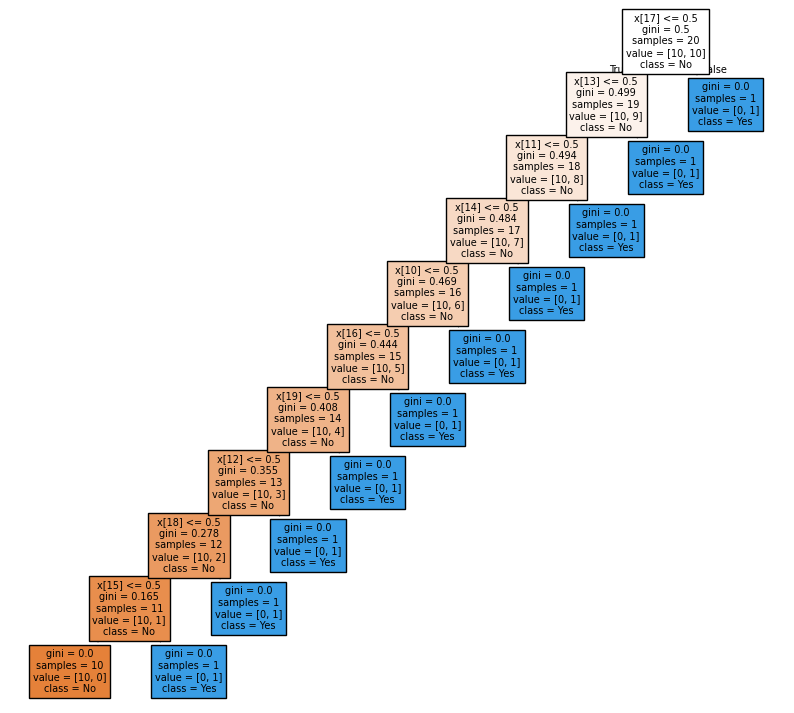

In [3]:
encoder.fit(data.loc[:, ['CustomerID']])
transformedCustomerID = encoder.transform(data.loc[:, ['CustomerID']])
clf = tree.DecisionTreeClassifier(random_state=0)
clf = clf.fit(transformedCustomerID, data.loc[:, 'Insurance'])
fig = plt.figure(figsize=(10, 9))
tree.plot_tree(clf, class_names=['No', 'Yes'], filled=True)
plt.show()

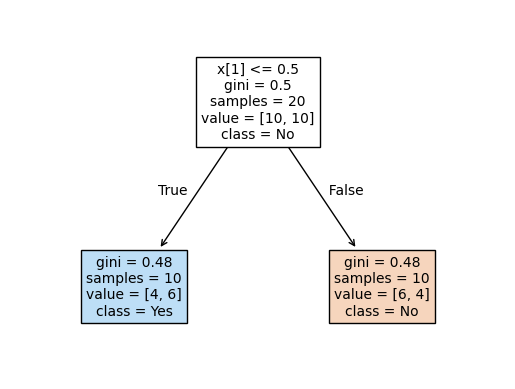

In [4]:
encoder.fit(data.loc[:, ['Sex']])
transformedSex = encoder.transform(data.loc[:, ['Sex']])
clf = tree.DecisionTreeClassifier(random_state=0)
clf = clf.fit(transformedSex, data.loc[:, 'Insurance'])
fig = plt.figure()
tree.plot_tree(clf, class_names=['No', 'Yes'], filled=True, fontsize=10)
plt.show()

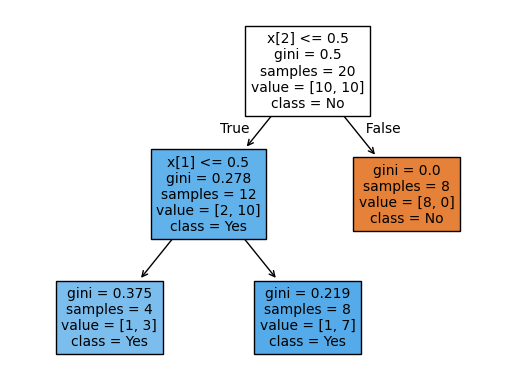

In [5]:
encoder.fit(data.loc[:, ['CarType']])
transformedCarType = encoder.transform(data.loc[:, ['CarType']])
clf = tree.DecisionTreeClassifier(random_state=0)
clf = clf.fit(transformedCarType, data.loc[:, 'Insurance'])
fig = plt.figure()
tree.plot_tree(clf, class_names=['No', 'Yes'], filled=True, fontsize=10)
plt.show()

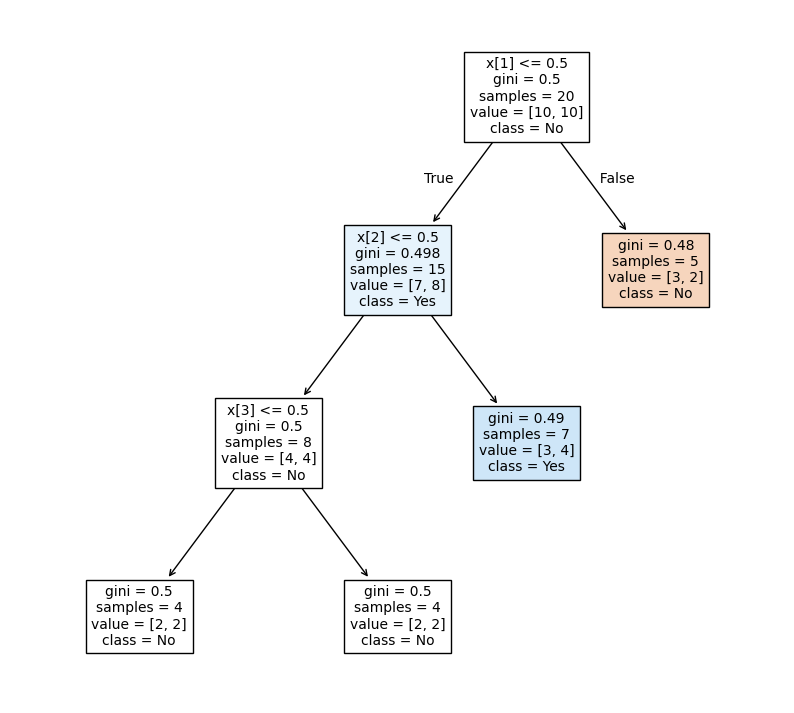

In [6]:
encoder.fit(data.loc[:, ['Budget']])
transformedBudget = encoder.transform(data.loc[:, ['Budget']])
clf = tree.DecisionTreeClassifier(random_state=0)
clf = clf.fit(transformedBudget, data.loc[:, 'Insurance'])
fig = plt.figure(figsize=(10, 9))
tree.plot_tree(clf, class_names=['No', 'Yes'], filled=True, fontsize=10)
plt.show()

In [7]:
absfreq = pd.crosstab(data.Sex, data.Insurance)
freq = pd.crosstab(data.Sex, data.Insurance, normalize='index')
freqSum = pd.crosstab(data.Sex, data.Insurance, normalize='all').sum(axis=1)
GINI_M = 1 - freq.loc["M", "No"]**2 - freq.loc["M", "Yes"]**2
GINI_F = 1 - freq.loc["F", "No"]**2 - freq.loc["F", "Yes"]**2
GINI_Sex = freqSum.loc["M"] * GINI_M + freqSum["F"] * GINI_F
print(GINI_Sex)

0.48


In [8]:
absfreq = pd.crosstab(data.CarType, data.Insurance)
freq = pd.crosstab(data.CarType, data.Insurance, normalize='index')
freqSum = pd.crosstab(data.CarType, data.Insurance, normalize='all').sum(axis=1)
GINI_Family = 1 - freq.loc["Family", "No"]**2 - freq.loc["Family", "Yes"]**2
GINI_Sport = 1 - freq.loc["Sport", "No"]**2 - freq.loc["Sport", "Yes"]**2
GINI_Sedan = 1 - freq.loc["Sedan", "No"]**2 - freq.loc["Sedan", "Yes"]**2
GINI_CarType = freqSum.loc["Family"] * GINI_Family + freqSum["Sport"] * GINI_Sport + freqSum.loc["Sedan"] * GINI_Sedan
print(GINI_CarType)

0.1625


In [9]:
absfreq = pd.crosstab(data.Budget, data.Insurance)
freq = pd.crosstab(data.Budget, data.Insurance, normalize='index')
freqSum = pd.crosstab(data.Budget, data.Insurance, normalize='all').sum(axis=1)
GINI_Low = 1 - freq.loc["Low", "No"]**2 - freq.loc["Low", "Yes"]**2
GINI_Medium = 1 - freq.loc["Medium", "No"]**2 - freq.loc["Medium", "Yes"]**2
GINI_High = 1 - freq.loc["High", "No"]**2 - freq.loc["High", "Yes"]**2
GINI_VeryHigh = 1 - freq.loc["VeryHigh", "No"]**2 - freq.loc["VeryHigh", "Yes"]**2
GINI_Budget = freqSum.loc["Low"] * GINI_Low + freqSum["Medium"] * GINI_Medium + freqSum.loc["High"] * GINI_High + freqSum["VeryHigh"] * GINI_VeryHigh
print(GINI_Budget)

0.49142857142857144
